# LAB 10 — Extractive Question Answering

## Notebook 2: Fine-tuning, Metrics, Experiments and Application

Các mục 17–36 theo W10.pdf. CSV được lưu trong `result/`; PNG hiển thị trực tiếp trong notebook và có bản trong thư mục lab10.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from qa_model import ROOT, RESULT_DIR, run_all
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS or not (RESULT_DIR/"results.csv").exists():
    run_all()
else:
    print("Đang đọc kết quả đã tạo; đặt RUN_EXPERIMENTS=True để chạy lại toàn bộ train/evaluation.")

D:\NLP_exercise\lab6\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Đang đọc kết quả đã tạo; đặt RUN_EXPERIMENTS=True để chạy lại toàn bộ train/evaluation.


## 17. Experiment 2 — Pretrained QA Model

Fine-tune BERT-Tiny trên SQuAD sample. Báo cáo train loss, validation loss, EM và F1; learning curves bắt buộc.

,epoch,train_loss,validation_loss,validation_em,validation_f1
0,1,4.9672,4.4911,0.0233,0.0884
1,2,4.3668,4.2636,0.0267,0.0994
2,3,4.1724,4.1571,0.0233,0.0874


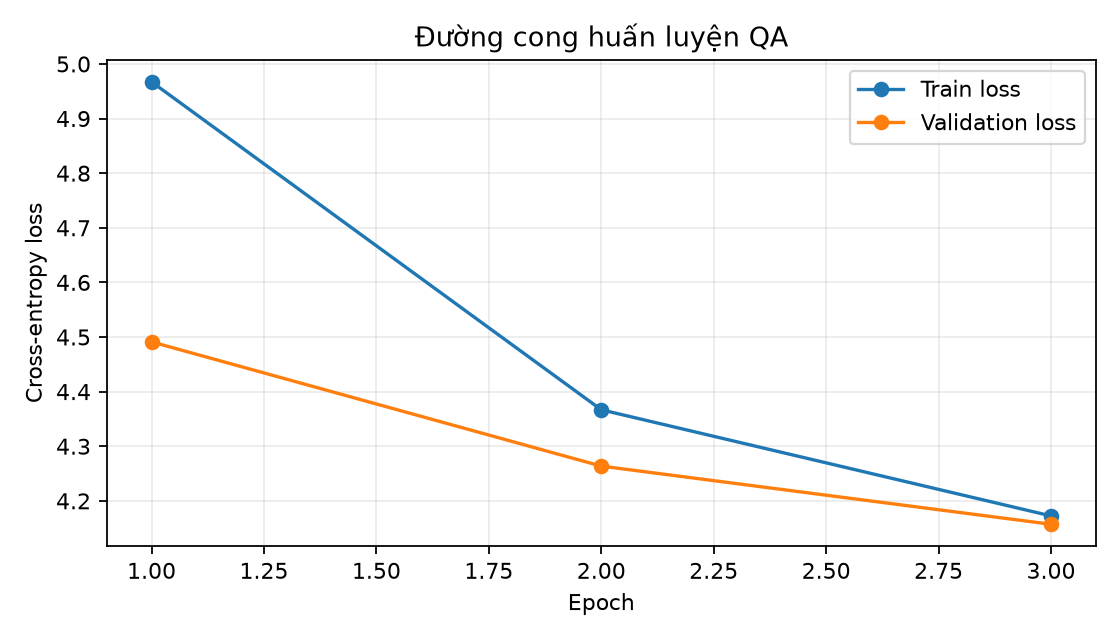

In [2]:
history=pd.read_csv(RESULT_DIR/"learning_curves.csv")
display(history.round(4))
display(Image(filename=str(ROOT/"learning_curves.png")))

### Phân tích kết quả Experiment 2

Train loss giảm qua ba epoch (4.967 → 4.367 → 4.172); validation loss cũng giảm (4.491 → 4.264 → 4.157). Validation F1 lần lượt là 0.088, 0.099 và 0.087; checkpoint tốt nhất được chọn ở epoch 2 theo validation F1.

Loss giảm cho thấy mô hình ngày càng khớp các vị trí start/end trên tập train và validation, nhưng điểm test vẫn chỉ đạt EM 0.050, F1 0.128. Điều này nhắc rằng loss thấp hơn không đồng nghĩa toàn bộ span dự đoán đúng; cấu hình BERT-Tiny, tập train rút gọn và thời lượng fine-tune cũng giới hạn kết quả.

## 18. Exact Match

EM bằng 1 nếu prediction khớp gold sau normalization; `Paris` và `the city of Paris` không nhất thiết khớp hoàn toàn.

In [3]:
from qa_model import normalize_answer
gold="Paris"; pred="the city of Paris"
print({"normalized_gold":normalize_answer(gold),"normalized_prediction":normalize_answer(pred),"EM":int(normalize_answer(gold)==normalize_answer(pred))})

{'normalized_gold': 'paris', 'normalized_prediction': 'city of paris', 'EM': 0}


## 19. Token-level F1 for QA

Gold `Paris France`, prediction `France`: overlap=1, precision=1, recall=0.5 và F1=0.667. F1 nhận biết partial match trong khi EM nghiêm ngặt.

In [4]:
from qa_model import qa_f1
print({"gold":"Paris France","prediction":"France","precision":1.0,"recall":0.5,"F1":qa_f1("France","Paris France"),"EM":0})

{'gold': 'Paris France', 'prediction': 'France', 'precision': 1.0, 'recall': 0.5, 'F1': 0.6666666666666666, 'EM': 0}


## 20. Experiment 3 — EM vs F1

So sánh baseline và fine-tuned Transformer trên cùng test split. Các ví dụ EM=0/F1>0 minh họa đáp án có token đúng nhưng span chưa trùng hoàn toàn.

,model,test_examples,em,f1,training_seconds
0,Keyword baseline,500,0.038,0.143,0.00
1,BERT-Tiny fine-tuned,500,0.050,0.128,292.28


,question,gold_answer,prediction,em,f1
0,How many bodies of water makes up Lake Constan...,three,three bodies of water: the Obersee,0.0,0.888889
1,Who was the head of the company?,Richard Dean Adams,1893 Richard Dean Adams,0.0,0.857143
2,Where does the livestock of the country normal...,the semi-arid savanna to the north and east,Livestock predominates in the semi-arid savann...,0.0,0.800000
3,What kind of cell did cynaobacteria enter long...,eukaryotic,eukaryotic cell,0.0,0.800000
4,Who was the Most Valuable Player for the 2015 ...,Cam Newton,quarterback Cam Newton,0.0,0.800000


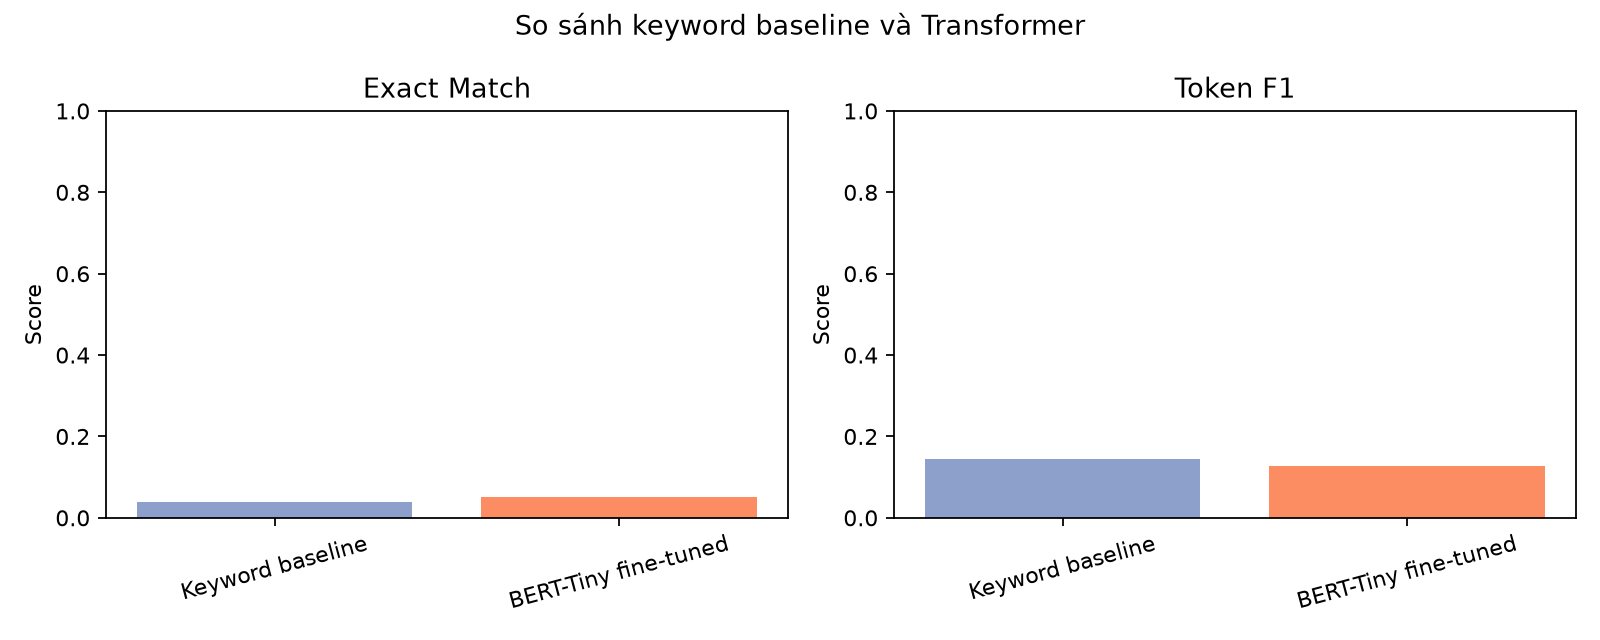

In [5]:
comparison=pd.read_csv(RESULT_DIR/"results.csv")
display(comparison.round(3))
partial=pd.read_csv(RESULT_DIR/"em0_f1positive_examples.csv")
display(partial[["question","gold_answer","prediction","em","f1"]].head(5))
display(Image(filename=str(ROOT/"em_f1_analysis.png")))

### Thảo luận và trả lời câu hỏi Experiment 3

Trên cùng 500 câu test, keyword baseline đạt EM **0.038** và F1 **0.143**; BERT-Tiny fine-tuned đạt EM **0.050** và F1 **0.128**. Transformer có EM cao hơn nhưng F1 thấp hơn baseline, nên lần chạy này không cho thấy mô hình nào tốt hơn trên cả hai metric.

Các ví dụ bên trên có EM=0 nhưng F1>0 vì prediction chứa một phần token của gold nhưng thêm hoặc lấy thừa từ: `three bodies of water: the Obersee` chứa gold `three`; `1893 Richard Dean Adams` chứa `Richard Dean Adams`; `eukaryotic cell` chứa gold `eukaryotic`; `quarterback Cam Newton` chứa gold `Cam Newton`. F1 ghi nhận phần token giao nhau, còn EM yêu cầu span sau chuẩn hóa khớp toàn bộ nên vẫn bằng 0. Đây là khác biệt giữa khớp một phần và khớp hoàn toàn.

## 21. Baseline

Baseline chấm điểm candidate sentences theo keyword overlap giữa question/context, sau đó chọn một candidate span ngắn. Đây là heuristic đơn giản, không phải mô hình train.

## 22. Experiment 4 — Question/Context Matching

So sánh các nhóm lexical overlap thấp và cao để kiểm tra liệu kết quả có thay đổi rõ theo overlap. Việc chia nhóm chỉ là phép kiểm tra sơ bộ, chưa tạo distractor có kiểm soát.

In [6]:
matching=pd.read_csv(RESULT_DIR/"question_context_matching_metrics.csv")
display(matching.round(3))

,matching_group,count,mean_overlap,em,f1
0,High overlap,161,0.910,0.050,0.127
1,Low overlap,138,0.406,0.036,0.127


### Thảo luận Experiment 4

Nhóm lexical overlap thấp có 138 câu, EM=0.036, F1=0.127; nhóm overlap cao có 161 câu, EM=0.050, F1=0.127. F1 gần như bằng nhau; EM cao hơn nhẹ ở nhóm overlap cao. Với cách chia nhóm theo tứ phân vị này, không thấy F1 tăng rõ khi từ vựng question/context trùng nhiều hơn.

Đây chưa phải thí nghiệm nhân quả: các nhóm có thể khác về loại câu hỏi, độ dài đáp án và độ khó context; phép đo overlap cũng không trực tiếp tạo cặp paraphrase/distractor có kiểm soát. Vì vậy chỉ kết luận rằng trong mẫu này lexical overlap đơn lẻ không giải thích đủ chênh lệch hiệu quả.

## 23. Experiment 5 — Answer Length

Nhóm gold answer thành 1, 2–3, 4–6 và 7+ token; báo cáo count, EM và F1. Cần đọc count cùng score, nhất là nhóm ít ví dụ.

,answer_length_group,count,em,f1
0,1,158,0.032,0.083
1,2–3,213,0.066,0.139
2,4–6,91,0.033,0.145
3,7+,38,0.079,0.209


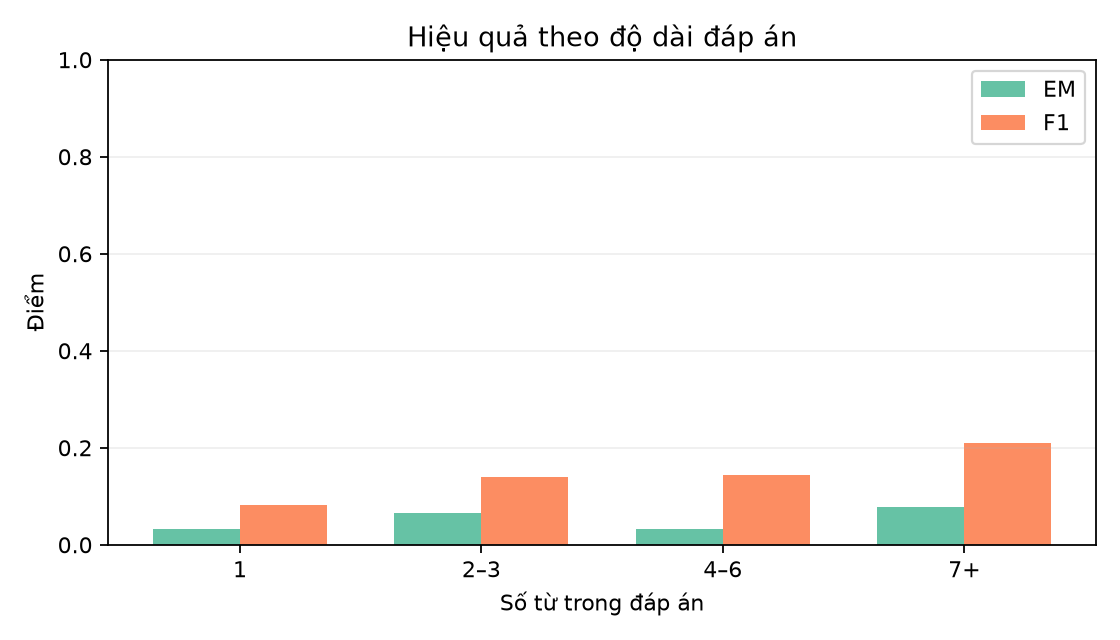

In [7]:
answer_length=pd.read_csv(RESULT_DIR/"answer_length_analysis.csv")
display(answer_length.round(3))
display(Image(filename=str(ROOT/"answer_length_analysis.png")))

### Đối chiếu với prediction ban đầu — Experiment 5

Prediction ban đầu cho rằng answer dài sẽ làm boundary khó hơn và F1 giảm. Kết quả quan sát được:

| Độ dài đáp án (từ tách bằng khoảng trắng) | Số mẫu | EM | F1 |
|---|---:|---:|---:|
| 1 | 158 | 0.032 | 0.083 |
| 2-3 | 213 | 0.066 | 0.139 |
| 4-6 | 91 | 0.033 | 0.145 |
| 7+ | 38 | 0.079 | 0.209 |

Xu hướng F1 **không giảm theo độ dài** trong mẫu này; nhóm 7+ có F1 cao nhất, nhưng chỉ có 38 câu. EM cũng không tăng đều giữa các nhóm. Vì vậy prediction ban đầu chưa được ủng hộ bởi số liệu hiện tại; nhóm dài có ít mẫu và khác biệt về nội dung, nên không suy ra rằng đáp án dài dễ hơn nói chung.

## 24. Error Analysis

Bảng lưu ít nhất năm ví dụ wrong start, wrong end và wrong span. Phân loại partial answer, distractor/không giao token, boundary sai, context dài hoặc ambiguity chỉ khi context hỗ trợ nhận định đó.

In [8]:
errors=pd.read_csv(RESULT_DIR/"error_examples.csv")
display(errors[["error_group","question","gold_answer","prediction","em","f1"]].head(15))
display(Markdown((ROOT/"error_analysis.md").read_text(encoding="utf-8")))

,error_group,question,gold_answer,prediction,em,f1
0,Wrong start,What was the name of the telegraph company Tes...,Budapest Telephone Exchange,"Ferenc Puskás at a telegraph company, the Buda...",0.0,0.545455
1,Wrong start,Where does the livestock of the country normal...,the semi-arid savanna to the north and east,Livestock predominates in the semi-arid savann...,0.0,0.800000
2,Wrong start,How long has free movement and trade been cent...,1957,"EU law in 2007, free movement and trade were c...",0.0,0.434783
3,Wrong start,What was the name of the set top box manufactu...,Thomson,STB) from manufacturer Thomson,0.0,0.400000
4,Wrong start,Who was the head of the company?,Richard Dean Adams,1893 Richard Dean Adams,0.0,0.857143
5,Wrong start,Where does the Middle Rhine flow between Binge...,Rhine Gorge,Middle Rhine flows through the Rhine Gorge,0.0,0.500000
6,Wrong start,What country showed all three episodes of Silv...,New Zealand,1988 story Silver Nemesis was broadcast with a...,0.0,0.190476
7,Wrong start,What modern city did Khanbaliq become?,Beijing,Khanbaliq (modern Beijing,0.0,0.500000
8,Wrong start,How are pharmacists regulated in most jurisdic...,separately from physicians,most jurisdictions (such as the United States)...,0.0,0.400000
9,Wrong start,During what period the drainage basin of the A...,the mid-Eocene,mid-Eocene,1.0,1.000000


# Error analysis — Lab 10

Trên test split có 500 câu hỏi: sai ký tự bắt đầu ở 461 câu, sai ký tự kết thúc ở 462 câu và span không khớp hoàn toàn ở 483 câu. Một ví dụ có thể xuất hiện ở nhiều nhóm.

## Ví dụ sai start, sai end và sai span

| Nhóm lỗi | Question | Gold | Prediction | Explanation | EM | F1 |
|---|---|---|---|---|---:|---:|
| Wrong start | What was the name of the telegraph company Tesla returned to after it became functional? | Budapest Telephone Exchange | Ferenc Puskás at a telegraph company, the Budapest Telephone Exchange | Sai start boundary; end chính xác. | 0 | 0.545 |
| Wrong start | Where does the livestock of the country normally dominate? | the semi-arid savanna to the north and east | Livestock predominates in the semi-arid savanna to the north and east | Sai start boundary; end chính xác. | 0 | 0.800 |
| Wrong start | How long has free movement and trade been central to European development? | 1957 | EU law in 2007, free movement and trade were central to European development since the Treaty of Rome 1957 | Sai start boundary; end chính xác. | 0 | 0.435 |
| Wrong start | What was the name of the set top box manufacturer that BSkyB was having issues with? | Thomson | STB) from manufacturer Thomson | Sai start boundary; end chính xác. | 0 | 0.400 |
| Wrong start | Who was the head of the company? | Richard Dean Adams | 1893 Richard Dean Adams | Sai start boundary; end chính xác. | 0 | 0.857 |
| Wrong start | Where does the Middle Rhine flow between Bingen and Bonn? | Rhine Gorge | Middle Rhine flows through the Rhine Gorge | Sai start boundary; end chính xác. | 0 | 0.500 |
| Wrong start | What country showed all three episodes of Silver Nemesis before the BBC did? | New Zealand | 1988 story Silver Nemesis was broadcast with all three episodes airing back to back on TVNZ in New Zealand | Sai start boundary; end chính xác. | 0 | 0.190 |
| Wrong start | What modern city did Khanbaliq become? | Beijing | Khanbaliq (modern Beijing | Sai start boundary; end chính xác. | 0 | 0.500 |
| Wrong start | How are pharmacists regulated in most jurisdictions? | separately from physicians | most jurisdictions (such as the United States), pharmacists are regulated separately from physicians | Sai start boundary; end chính xác. | 0 | 0.400 |
| Wrong start | During what period the drainage basin of the Amazon likely split? | the mid-Eocene | mid-Eocene | Sai start boundary; end chính xác. | 1 | 1.000 |
| Wrong end | What is stage 1 in the life of a bill? | introductory | introductory stage of the bill | Sai end boundary; start chính xác. | 1 | 1.000 |
| Wrong end | How many bodies of water makes up Lake Constance?  | three | three bodies of water: the Obersee | Sai end boundary; start chính xác. | 0 | 0.889 |
| Wrong end | What is Kenya's literacy rate? | 85% | 85% of the whole population | Sai end boundary; start chính xác. | 0 | 0.400 |
| Wrong end | Who composed the original Doctor Who theme? | Ron Grainer | Ron Grainer and realised by Delia Derbyshire of the BBC Radiophonic Workshop, with assistance from Dick Mills | Sai end boundary; start chính xác. | 0 | 0.222 |
| Wrong end | What is another notable university in Warsaw after the University of Warsaw? | Polish Academy of Sciences | Polish Academy of Sciences and the University of Warsaw, two opera houses, theatres, museums, libraries and monuments | Sai end boundary; start chính xác. | 0 | 0.400 |
| Wrong end | What was Hero of Alexandria's nationality? | Greek | Greek mathematician Hero of Alexandria. In the following centuries, the few steam-powered "engines" known were, like the aeolipile | Sai end boundary; start chính xác. | 0 | 0.125 |
| Wrong end | In which year did Genghis Khan strike against the Tanguts? | 1226 | 1226, immediately after returning from the west, Genghis Khan began a retaliatory attack on the Tanguts | Sai end boundary; start chính xác. | 0 | 0.143 |
| Wrong end | What kind of cell did cynaobacteria enter long ago? | eukaryotic | eukaryotic cell | Sai end boundary; start chính xác. | 0 | 0.800 |
| Wrong end | What year did Genghis Khan die? | 1227 | 1227 after defeating the Western Xia | Sai end boundary; start chính xác. | 0 | 0.333 |
| Wrong end | Who did Rollo sign the treaty of Saint-Clair-sur-Epte with? | King Charles III | King Charles III of West Francia and the famed Viking ruler Rollo, and was situated in the former Frankish kingdom of Neustria | Sai end boundary; start chính xác. | 0 | 0.261 |
| Wrong span | Objects of constant density are proportional to volume by what force to define standard weights?. | gravity | two forces is the most usual way of measuring forces, using simple devices such as weighing scales and spring balances | Partial answer/span boundary sai. | 0 | 0.091 |
| Wrong span | How many square kilometres of the Amazon forest was lost by 1991? | 415,000 | 587 | Không giao token với gold; cần đọc context để xác định có phải distractor hay không. | 0 | 0.000 |
| Wrong span | What is economic liberalism one of the causes of? | economic inequality | John Schmitt and Ben Zipperer | Không giao token với gold; cần đọc context để xác định có phải distractor hay không. | 0 | 0.000 |
| Wrong span | What were the two forms of environmental determinism? | orientalism and tropicality | tropical environments were seen as "less civilized" therefore justifying colonial control as a civilizing mission | Không giao token với gold; cần đọc context để xác định có phải distractor hay không. | 0 | 0.000 |
| Wrong span | Excessive bureaucratic red tape is one of the reasons for what type of ownership? | extra-legal | 14 years to build on government land | Không giao token với gold; cần đọc context để xác định có phải distractor hay không. | 0 | 0.000 |
| Wrong span | What term best describes southern California's collection of landscapes? | varied | Pacific Ocean islands | Không giao token với gold; cần đọc context để xác định có phải distractor hay không. | 0 | 0.000 |
| Wrong span | What did frozen subsoil and expanded alpine glaciers begin to do? | thaw | 9000 BP, Europe | Không giao token với gold; cần đọc context để xác định có phải distractor hay không. | 0 | 0.000 |
| Wrong span | Where does the cold and warm water meet the warm water? | Rheinbrech | Hagnau am Bodensee. A small fraction of the flow is diverted off the island of Mainau into Lake Überlingen | Partial answer/span boundary sai. | 0 | 0.111 |
| Wrong span | The Los Angeles Rams are an example of what kind of sports team? | NFL | Los Angeles Rams, San Diego Chargers); NBA (Los Angeles Lakers, Los Angeles Clippers); MLB (Los Angeles Dodgers | Không giao token với gold; cần đọc context để xác định có phải distractor hay không. | 0 | 0.000 |
| Wrong span | What paleontologists are currently on the university's faculty? | Neil Shubin and Paul Sereno | Nobel prize winning physicist Yoichiro Nambu, Nobel prize winning physicist James Cronin, Nobel Prize winning economists Eugene Fama | Không giao token với gold; cần đọc context để xác định có phải distractor hay không. | 0 | 0.000 |

## Phân loại và nhận xét

Các trường hợp F1 > 0 nhưng EM = 0 là partial answer hoặc span có boundary sai. Trường hợp F1 = 0 là dự đoán không giao token với gold; có thể là distractor, nhầm vị trí hoặc span sai nhiều, nhưng cần đọc toàn context trước khi gán nguyên nhân cụ thể. Bảng ranh giới cho biết chính xác đầu mút nào lệch; phần giải thích nguyên nhân sâu hơn cần kiểm tra thủ công từng context.

## Wrong start so với wrong end

- Wrong start: 461/500.
- Wrong end: 462/500.
- Wrong span: 483/500.

Các số đo start/end dùng character boundaries so với đáp án chuẩn đầu tiên của SQuAD; EM/F1 lấy điểm tốt nhất trong các đáp án tham chiếu.


### Nhận xét Error Analysis

Bảng phía trên có 10 ví dụ start sai nhưng end đúng, 10 ví dụ end sai nhưng start đúng và 10 ví dụ span không khớp hoàn toàn. Các trường hợp F1>0 thường là đáp án một phần hoặc span lấy thừa; F1=0 nghĩa là không có token giao với gold. Không thể chỉ từ F1=0 kết luận nguyên nhân chắc chắn là distractor: cần đọc context để phân biệt nhầm vị trí, câu hỏi mơ hồ, context dài hoặc thiếu bằng chứng. Các lỗi truncation/tokenization cũng cần đối chiếu offset/window cụ thể trước khi gán nhãn.

## 25. Wrong Start vs Wrong End

Wrong start là lệch ký tự đầu; wrong end là lệch ký tự kết thúc. `New York` so với `New York City` minh họa end sai; `York City` minh họa start sai.

In [9]:
predictions=pd.read_csv(RESULT_DIR/"token_predictions.csv")
boundaries=pd.DataFrame([{"measure":"Wrong start","count":int((predictions.start_correct==0).sum())},{"measure":"Wrong end","count":int((predictions.end_correct==0).sum())},{"measure":"Wrong complete span","count":int((predictions.span_exact==0).sum())}])
display(boundaries)

,measure,count
0,Wrong start,461
1,Wrong end,462
2,Wrong complete span,483


### Trả lời câu hỏi: Wrong start hay wrong end phổ biến hơn?

Theo so sánh với đáp án tham chiếu đầu tiên, có **461/500** trường hợp sai start và **462/500** sai end; số lượng gần như ngang nhau, end nhiều hơn một trường hợp. Có 21 trường hợp chỉ sai start, 22 trường hợp chỉ sai end và 440 trường hợp sai cả hai đầu mút. Như vậy lỗi chủ yếu không nghiêng rõ về một phía; nhiều dự đoán lệch cả span.

Đây là thống kê ranh giới ký tự so với câu trả lời tham chiếu đầu tiên; EM/F1 chọn điểm tốt nhất trên các reference của SQuAD, nên hai cách đếm không nhất thiết trùng nhau. Một giả thuyết là mô hình còn chọn nhầm vùng chứa thông tin gần đúng thay vì định vị chính xác cả hai đầu mút; cần kiểm tra từng context để xác nhận nguyên nhân.

## 26. No-Answer Extension

Thử nghiệm này dùng SQuAD v1.1 answerable examples. Không có no-answer head/threshold; SQuAD 2.0 là phần mở rộng và không được tuyên bố đã giải quyết.

## 27. Application — Document QA

CLI nhận question cùng context hoặc tệp văn bản, rồi trả về span trích từ tài liệu. Context được cung cấp trực tiếp như yêu cầu Lab 10.

In [10]:
from document_qa import answer_question, DEMO_CONTEXT
question="When was the Eiffel Tower completed?"
answer=answer_question(question,DEMO_CONTEXT)
display(pd.DataFrame([{"question":question,"document":DEMO_CONTEXT,"predicted_answer":answer}]))

,question,document,predicted_answer
0,When was the Eiffel Tower completed?,The Eiffel Tower is a wrought-iron lattice tow...,Gustave Eiffel's company


## 28. QA và RAG

Extractive QA nhận sẵn question+context và chọn span. RAG có retriever tìm tài liệu liên quan trước, rồi generator hoặc QA model tạo/trích câu trả lời.

## 29. AI Usage Disclosure

AI hỗ trợ tạo boilerplate, khung code, notebook và visualization. W10 giới hạn AI trong các phần alignment/tính toán/prediction/metric/error analysis/reflection; sinh viên cần tự xác minh, hiểu và chỉnh sửa các phần này trước khi nộp.

## 30. Reproducibility

Ghi model, tokenizer, dataset, split, max length, stride, batch, learning rate, epoch, optimizer, seed, hardware và thời gian train.

In [11]:
repro=json.loads((RESULT_DIR/"reproducibility.json").read_text(encoding="utf-8"))
display(pd.DataFrame([repro]).T.rename(columns={0:"value"}))

,value
dataset,SQuAD v1.1
seed,2026
model,prajjwal1/bert-tiny
train_examples,3000
validation_examples,300
test_examples,500
max_length,384
stride,128
batch_size,16
learning_rate,0.00003


## 31. Deliverables

Danh sách dưới đây chỉ rõ notebook, code, CSV, PNG và phần viết tay/tự luận nằm trong thư mục Lab 10.

In [12]:
files=["README.md","calculations.md","prediction.md","tokenizer_alignment.ipynb","qa_model.py","qa_finetuning.ipynb","result/results.csv","learning_curves.png","em_f1_analysis.png","answer_length_analysis.png","error_analysis.md","document_qa.py","reflection.md"]
display(pd.DataFrame([{"deliverable":p,"exists":(ROOT/p).exists()} for p in files]))

,deliverable,exists
0,README.md,True
1,calculations.md,True
2,prediction.md,True
3,tokenizer_alignment.ipynb,True
4,qa_model.py,True
5,qa_finetuning.ipynb,True
6,result/results.csv,True
7,learning_curves.png,True
8,em_f1_analysis.png,True
9,answer_length_analysis.png,True


## 32. Rubric

Thang điểm từ W10.pdf gồm theory/calculation, prediction, tokenization/alignment, baseline, model, metrics, controlled experiments, error analysis, application và reflection.

| Thành phần | Điểm |
|---|---:|
| Theory & calculation | 10 |
| Prediction | 10 |
| Tokenization & span alignment | 15 |
| Baseline | 10 |
| QA model implementation | 15 |
| EM/F1 evaluation | 10 |
| Controlled experiments | 10 |
| Error analysis | 10 |
| Document QA application | 5 |
| Reflection | 5 |
| **Tổng** | **100** |

## 33. Individual Learning Check

Trả lời 12 câu hỏi cuối lab về extractive QA, span endpoints, offset mapping, stride, EM/F1, start/end, RAG và unanswerable questions.

1. Classification dự đoán một nhãn cho toàn văn bản; extractive QA dự đoán một đoạn con trong context.
2. Start/end xác định cả vị trí bắt đầu và kết thúc của span.
3. Character offset đếm ký tự trong văn bản gốc; token index đếm phần tử sau tokenizer.
4. Offset mapping liên kết token với vị trí ký tự để ánh xạ nhãn SQuAD sang token.
5. Stride tạo overlap giữa các cửa sổ để không bỏ lỡ answer quanh ranh giới.
6. Context có thể dài hơn giới hạn chiều dài đầu vào của mô hình.
7. EM đo span có khớp hoàn toàn sau chuẩn hóa hay không.
8. QA F1 đo precision/recall trên các token giao nhau; accuracy thường đếm dự đoán đúng/sai ở cấp mẫu hoặc nhãn.
9. Prediction có thể chứa một phần token gold nên F1 dương, nhưng span chưa khớp hoàn toàn nên EM bằng 0.
10. Wrong start là sai boundary đầu; wrong end là sai boundary cuối.
11. Extractive QA nhận context đã có; RAG truy xuất tài liệu liên quan rồi mới đưa context cho model trả lời.
12. QA không thể trả lời đúng khi context thiếu bằng chứng, câu hỏi không answerable, hoặc đáp án bị loại khỏi window.

## 34. Reflection

Phản ánh 300–500 từ, so sánh Lab 08/09/10 và giải thích vì sao backbone giống nhau nhưng prediction head/target khác nhau.

Trong Lab 08, Lab 09 và Lab 10, pretrained Transformer được dùng làm backbone để tạo biểu diễn ngữ cảnh, nhưng mỗi bài toán cần đầu ra và prediction head khác nhau. Ở Lab 08, mô hình phân loại toàn câu: thường lấy hidden state của token [CLS] rồi đưa qua linear head để chọn một nhãn cho văn bản. Ở Lab 09, mô hình nhận một nhãn tại mỗi vị trí token, chẳng hạn BIO, nên classifier được áp dụng lên từng contextual representation. Lab 10 chuyển sang extractive QA: đầu vào là question cùng context, còn mục tiêu là hai vị trí start và end xác định một span trích nguyên văn từ context. Như vậy backbone có thể tương tự, nhưng target của loss quyết định head và cách diễn giải dự đoán.

Trong Lab 10, dữ liệu SQuAD được ánh xạ từ answer_start theo ký tự sang token span thông qua offset mapping. Đây là bước cần thiết vì ký tự, từ và subword không dùng chung chỉ số. Khi context dài, sliding window với stride giúp bao phủ vùng cuối đoạn và giữ đáp án nằm gần biên hai cửa sổ. Loss là trung bình cross-entropy cho start và end; cần cả hai vì một đầu mút đúng chưa đủ xác định toàn bộ câu trả lời. Exact Match kiểm tra span sau chuẩn hóa có khớp hoàn toàn không, còn token F1 ghi nhận phần từ giao nhau.

Với cấu hình thử nghiệm này, BERT-Tiny fine-tune trên 3.000 câu train trong 3 epoch đạt test EM 0.050 và F1 0.128; keyword baseline đạt EM 0.038 và F1 0.143. Transformer có EM cao hơn nhưng token F1 thấp hơn baseline, nên kết quả không ủng hộ kết luận rằng mô hình pretrained luôn tốt hơn. Validation F1 tốt nhất đạt 0.099; test vẫn chỉ được dùng để báo cáo cuối, không chọn epoch. Thử nghiệm độ dài cho F1 0.044, 0.082, 0.086 lần lượt ở 128, 256 và 384 token. Nhóm đáp án 7+ từ có F1 0.209, nhưng chỉ có 38 mẫu, nên không thể kết luận span dài dễ hơn.

Các số liệu này chịu ảnh hưởng của BERT-Tiny, tập con SQuAD và giới hạn huấn luyện trên CPU; chúng không đại diện cho mọi Transformer. Error analysis cho thấy cần xem riêng điểm bắt đầu, điểm kết thúc và toàn span, vì dự đoán gần đúng có thể có F1 dương nhưng EM bằng 0. Lab 10 giả định context đã có sẵn; Lab 11 bổ sung retrieval để tìm tài liệu liên quan, rồi Lab 12 kết hợp retrieval với generation trong RAG.

## 35. Bridge to LAB 11

Lab 10 giả định context đã biết. Lab 11 thêm semantic retrieval để tìm top-K tài liệu trong collection lớn; Lab 12 kết hợp retrieval và generation.

| Lab | Input | Output chính |
|---|---|---|
| Lab 10 | Question + known context | Answer span |
| Lab 11 | Question + document collection | Top-K relevant documents |
| Lab 12 | Question + retriever + generator | Grounded generated answer |

## 36. Mosaic LAB 08–12

Chuỗi bài toán: classification → token prediction → span prediction → semantic retrieval → RAG. Backbone tạo contextual representations, còn head và target quy định chức năng.

```text
LAB 08: document → [CLS] → classification label
LAB 09: sentence → token representations → BIO labels
LAB 10: question + context → start/end positions → answer span
LAB 11: question + corpus → embeddings/retrieval → relevant documents
LAB 12: retriever + generator → RAG answer
```